# Fraude em cartões | Comparação de modelos
**Objetivo.** Encontrar transações fraudulentas sem sobrecarregar a revisão com falsos positivos. As métricas de interesse são recall, precisão e F1 para a classe 1.

A base [Credit Card Fraud Detection (ULB/Kaggle)](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) contém 284.807 transações, das quais 492 são fraudes. As variáveis V1 a V28 são componentes PCA anonimizados. Este experimento reproduz o desafio em ambiente educacional.

**Protocolo.** Divisão estratificada em treino (60%), validação (20%) e teste (20%). Os modelos aprendem no treino. A validação orienta a escolha de modelo e limiar. O teste fica reservado para a avaliação final. No Colab, use **Executar tudo**.

In [1]:
%pip -q install pandas==2.2.3 scikit-learn==1.8.0 xgboost-cpu==3.4.1 shap==0.54.1 matplotlib==3.10.8 requests==2.34.2


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import tempfile
import zipfile
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay,
    precision_score, recall_score, f1_score)
from xgboost import XGBClassifier

SEED = 42
URL = 'https://www.kaggle.com/api/v1/datasets/download/mlg-ulb/creditcardfraud'
cache = Path(tempfile.gettempdir()) / 'fraud-data'
cache.mkdir(exist_ok=True)
archive = cache / 'creditcard.zip'
if not zipfile.is_zipfile(archive):
    partial = archive.with_suffix('.part')
    with requests.get(URL, stream=True, timeout=(20, 120)) as response:
        response.raise_for_status()
        with partial.open('wb') as handle:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                handle.write(chunk)
    if not zipfile.is_zipfile(partial):
        raise ValueError('O link público não retornou o ZIP esperado.')
    partial.replace(archive)
with zipfile.ZipFile(archive) as z, z.open('creditcard.csv') as csv:
    df = pd.read_csv(csv)

expected = ['Time', *[f'V{i}' for i in range(1, 29)], 'Amount', 'Class']
assert list(df.columns) == expected
assert len(df) == 284_807 and df['Class'].sum() == 492
assert not df.isna().any().any() and df['Amount'].ge(0).all()
display(df.head())
display(pd.DataFrame({
    'transações': df['Class'].value_counts(),
    'percentual': df['Class'].value_counts(normalize=True).mul(100),
}).rename(index={0:'Normal', 1:'Fraude'}).round(4))

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


,transações,percentual
Class,,
Normal,284315,99.8273
Fraude,492,0.1727


## Preparação e desbalanceamento

`Amount` recebe `log1p` antes da padronização. A transformação usa a mesma sequência em todos os modelos e o scaler aprende em cada ajuste do pipeline, inclusive dentro da validação cruzada. Mantive `Time` como tempo relativo. O protocolo aleatório estratificado favorece a comparação didática e não mede desempenho em transações de um período futuro.

A classe rara recebe pesos no Random Forest e no XGBoost. A regressão logística é a linha de base aprendida, sem ponderação. O modelo constante ilustra a armadilha da acurácia.

In [3]:
X = df.drop(columns='Class')
y = df['Class']
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=.25, stratify=y_dev, random_state=SEED)
display(pd.DataFrame({
    tag: {'Transações':len(target), 'Fraudes':int(target.sum()), '% fraude':100*target.mean()}
    for tag, target in [('Treino',y_train),('Validação',y_val),('Teste',y_test)]
}).T.round(4))

def pipeline(estimator):
    amount = Pipeline([('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                       ('scale', StandardScaler())])
    pre = ColumnTransformer([('valor', amount, ['Amount']),
                             ('restante', StandardScaler(), [x for x in X.columns if x != 'Amount'])],
                            verbose_feature_names_out=False)
    return Pipeline([('prep', pre), ('modelo', estimator)])

weight = (y_train == 0).sum() / (y_train == 1).sum()
models = {
    'Sempre normal': pipeline(DummyClassifier(strategy='most_frequent')),
    'Regressão logística': pipeline(LogisticRegression(max_iter=500, random_state=SEED)),
    'Random Forest': pipeline(RandomForestClassifier(n_estimators=90, max_depth=14,
        class_weight='balanced', random_state=SEED, n_jobs=4)),
    'XGBoost': pipeline(XGBClassifier(n_estimators=110, max_depth=4, learning_rate=.1,
        scale_pos_weight=weight, tree_method='hist', eval_metric='logloss', random_state=SEED, n_jobs=4)),
}
for model in models.values():
    model.fit(X_train, y_train)

grid = GridSearchCV(
    pipeline(XGBClassifier(n_estimators=100, scale_pos_weight=weight, tree_method='hist',
        eval_metric='logloss', random_state=SEED, n_jobs=2)),
    {'modelo__max_depth':[3,5], 'modelo__learning_rate':[.07,.14]},
    cv=StratifiedKFold(3, shuffle=True, random_state=SEED), scoring='recall', n_jobs=2)
from joblib import parallel_backend
with parallel_backend("threading"):
    grid.fit(X_train, y_train)
models['XGBoost ajustado'] = grid.best_estimator_
print('Melhores parâmetros:', grid.best_params_)
display(pd.DataFrame(grid.cv_results_)[['params','mean_test_score','std_test_score']].round(4))

,Transações,Fraudes,% fraude
Treino,170883.0,295.0,0.1726
Validação,56962.0,99.0,0.1738
Teste,56962.0,98.0,0.1720


,params,mean_test_score,std_test_score
0,"{'modelo__learning_rate': 0.07, 'modelo__max_d...",0.8711,0.0556
1,"{'modelo__learning_rate': 0.07, 'modelo__max_d...",0.8340,0.0553
2,"{'modelo__learning_rate': 0.14, 'modelo__max_d...",0.8576,0.0500
3,"{'modelo__learning_rate': 0.14, 'modelo__max_d...",0.8169,0.0583


Melhores parâmetros: {'modelo__learning_rate': 0.07, 'modelo__max_depth': 3}


## Escolha do modelo e do limiar na validação

AP (average precision) resume o desempenho ao longo da curva precisão–recall. Escolhemos o modelo com maior AP na validação. Comparamos 0,50 e 0,30 e escolhemos o limiar com maior F1 de fraude na validação, usando recall como desempate. Essa decisão representa um critério didático. Em produção, o custo dos falsos positivos e das fraudes perdidas deve orientar o limiar.

Baixar o limiar pode ampliar a detecção, mas também pode gerar mais falsos alertas. Os escores de modelos ponderados não devem ser interpretados aqui como probabilidades calibradas.

In [4]:
def metrics(target, scores, threshold):
    pred = scores >= threshold
    tn, fp, fn, tp = confusion_matrix(target, pred, labels=[0,1]).ravel()
    return {'Precisão':precision_score(target,pred,zero_division=0),
            'Recall':recall_score(target,pred,zero_division=0), 'F1':f1_score(target,pred,zero_division=0),
            'VP':int(tp),'FP':int(fp),'FN':int(fn), 'VN':int(tn),
            'AP':average_precision_score(target,scores), 'ROC AUC':roc_auc_score(target,scores)}
val_scores = {name: model.predict_proba(X_val)[:,1] for name,model in models.items()}
val_table = pd.DataFrame({name:metrics(y_val,s,.5) for name,s in val_scores.items()}).T
display(val_table.round(4))
winner = val_table['AP'].idxmax()
thresholds = pd.DataFrame({t:metrics(y_val,val_scores[winner],t) for t in [.50,.30]}).T
thresholds.index.name='Limiar'
display(thresholds.round(4))
chosen = float(thresholds.sort_values(['F1','Recall'], ascending=False).index[0])
print(f'Modelo escolhido: {winner} | Limiar: {chosen:.2f}')

,Precisão,Recall,F1,VP,FP,FN,VN,AP,ROC AUC
Sempre normal,0.0000,0.0000,0.0000,0.0,0.0,99.0,56863.0,0.0017,0.5000
Regressão logística,0.8226,0.5152,0.6335,51.0,11.0,48.0,56852.0,0.7161,0.9671
Random Forest,0.8780,0.7273,0.7956,72.0,10.0,27.0,56853.0,0.7844,0.9347
XGBoost,0.5436,0.8182,0.6532,81.0,68.0,18.0,56795.0,0.7891,0.9707
XGBoost ajustado,0.1281,0.8384,0.2222,83.0,565.0,16.0,56298.0,0.7126,0.9746


,Precisão,Recall,F1,VP,FP,FN,VN,AP,ROC AUC
Limiar,,,,,,,,,
0.5,0.5436,0.8182,0.6532,81.0,68.0,18.0,56795.0,0.7891,0.9707
0.3,0.3744,0.8283,0.5157,82.0,137.0,17.0,56726.0,0.7891,0.9707


Modelo escolhido: XGBoost | Limiar: 0.50


## Avaliação final no teste

**Recall** divide os verdadeiros positivos pelo total de fraudes reais. **Precisão** divide os verdadeiros positivos pelo total de alertas. **F1** é a média harmônica dos dois. A curva ROC dá uma visão complementar. A curva precisão–recall explicita o custo dos falsos alertas sobre a classe rara, com a prevalência de fraudes como referência.

,Precisão,Recall,F1,VP,FP,FN,VN,AP,ROC AUC
Sempre normal,0.0000,0.0000,0.0000,0.0,0.0,98.0,56864.0,0.0017,0.5000
Regressão logística,0.8289,0.6429,0.7241,63.0,13.0,35.0,56851.0,0.7420,0.9547
Random Forest,0.8444,0.7755,0.8085,76.0,14.0,22.0,56850.0,0.8343,0.9706
XGBoost,0.5122,0.8571,0.6412,84.0,80.0,14.0,56784.0,0.8330,0.9752
XGBoost ajustado,0.1337,0.8980,0.2328,88.0,570.0,10.0,56294.0,0.7155,0.9723


,Precisão,Recall,F1,VP,FP,FN,VN,AP,ROC AUC
Limiar,,,,,,,,,
0.5,0.5122,0.8571,0.6412,84.0,80.0,14.0,56784.0,0.833,0.9752
0.3,0.3438,0.8980,0.4972,88.0,168.0,10.0,56696.0,0.833,0.9752


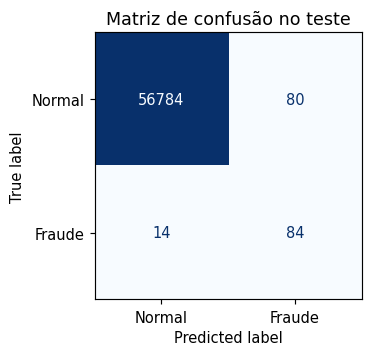

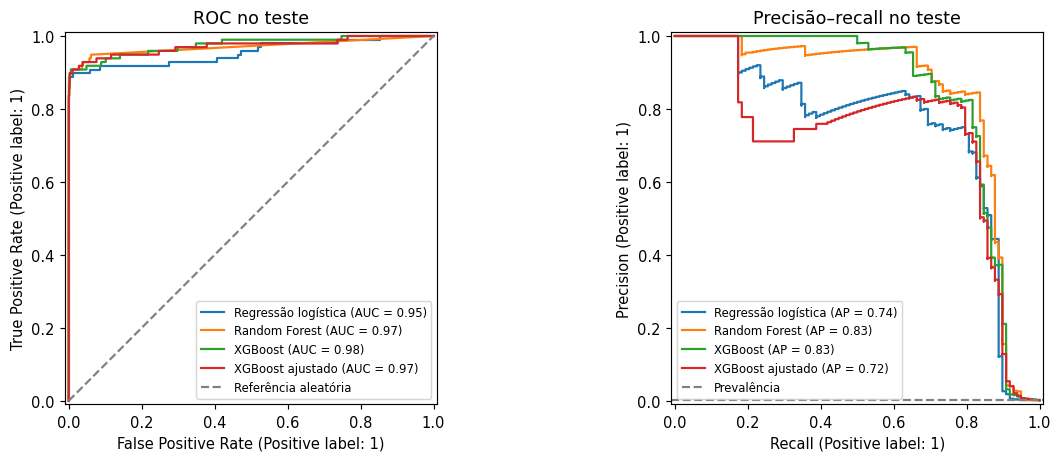

Relatório final: XGBoost | limiar=0.50
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     56864
      Fraude       0.51      0.86      0.64        98

    accuracy                           1.00     56962
   macro avg       0.76      0.93      0.82     56962
weighted avg       1.00      1.00      1.00     56962



In [5]:
test_scores = {name:model.predict_proba(X_test)[:,1] for name,model in models.items()}
test_table = pd.DataFrame({name:metrics(y_test,s,.5) for name,s in test_scores.items()}).T
decision_test = pd.DataFrame({t:metrics(y_test,test_scores[winner],t) for t in [.5,.3]}).T
decision_test.index.name='Limiar'
display(test_table.round(4))
display(decision_test.round(4))

pred = (test_scores[winner] >= chosen).astype(int)
print(f'Relatório final: {winner} | limiar={chosen:.2f}')
print(classification_report(y_test,pred,labels=[0,1],target_names=['Normal','Fraude'],zero_division=0))
fig,ax=plt.subplots(figsize=(4.7,3.5))
ConfusionMatrixDisplay.from_predictions(y_test,pred,labels=[0,1],
    display_labels=['Normal','Fraude'],cmap='Blues',colorbar=False,ax=ax)
ax.set_title('Matriz de confusão no teste')
fig.tight_layout()
plt.show()

fig,(ax1,ax2)=plt.subplots(1,2,figsize=(12,4.5))
for name,s in test_scores.items():
    if name == 'Sempre normal':
        continue
    RocCurveDisplay.from_predictions(y_test,s,name=name,ax=ax1)
    PrecisionRecallDisplay.from_predictions(y_test,s,name=name,ax=ax2)
ax1.plot([0,1],[0,1],'--',color='gray',label='Referência aleatória')
ax2.axhline(y_test.mean(),linestyle='--',color='gray',label='Prevalência')
ax1.set_title('ROC no teste')
ax2.set_title('Precisão–recall no teste')
ax1.legend(fontsize=8)
ax2.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Por que uma transação recebeu um alerta?

SHAP decompõe a saída do modelo em uma referência e contribuições por variável. A importância global abaixo é a média do valor absoluto de SHAP numa amostra aleatória do teste. O gráfico local mostra contribuições com sinal em um alerta verdadeiro positivo, quando disponível. Um componente PCA pode influenciar a decisão sem revelar o atributo original. As contribuições descrevem o modelo e não estabelecem causalidade.

,SHAP absoluto médio
V4,0.9159
V8,0.4514
V14,0.3000
V5,0.2625
V28,0.2167
V21,0.2012
V26,0.1810
V13,0.1648
V12,0.1626
V10,0.1599


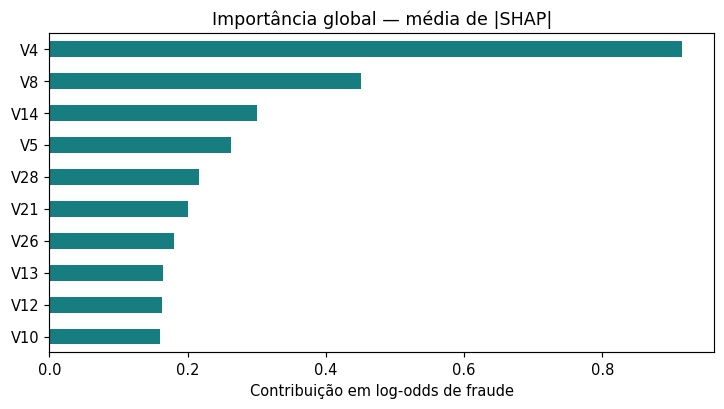

,Contribuição local
V14,4.7610
V12,3.3268
V10,1.9278
V4,1.4386
V11,1.2317


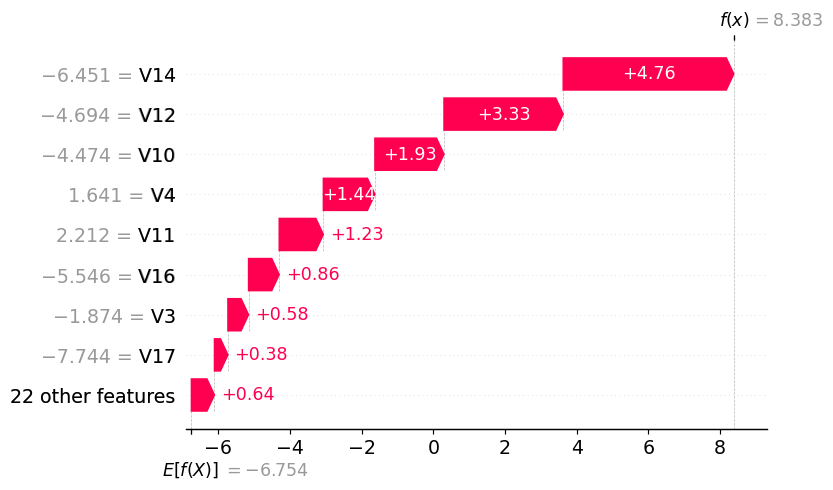

Exemplo no teste: linha 77348 | classe real=1 | escore=0.9998 | limiar=0.50


In [6]:
final = models[winner]
prep = final.named_steps['prep']
est = final.named_steps['modelo']
columns = ['log_Amount (padronizado)' if col=='Amount' else col
           for col in prep.get_feature_names_out()]
sample = X_test.sample(400, random_state=SEED)
known = np.flatnonzero((pred == 1) & (y_test.to_numpy() == 1))
alert = np.flatnonzero(pred == 1)
assert len(alert), 'Nenhum alerta para explicar no limiar escolhido.'
position = int(known[0] if len(known) else alert[0])
local = X_test.iloc[[position]]
background = prep.transform(X_train.sample(100,random_state=SEED))
if winner == 'Regressão logística':
    explainer = shap.LinearExplainer(est, background)
    units = 'log-odds de fraude'
else:
    explainer = shap.TreeExplainer(est, data=background)
    units = 'probabilidade de fraude' if winner == 'Random Forest' else 'log-odds de fraude'

def explain(frame):
    explanation = explainer(pd.DataFrame(prep.transform(frame),columns=columns))
    return explanation[...,1] if explanation.values.ndim == 3 else explanation

global_shap = explain(sample)
local_shap = explain(local)[0]
importance = (pd.Series(np.abs(global_shap.values).mean(axis=0),index=columns)
              .sort_values(ascending=False).head(10))
drivers = pd.Series(local_shap.values,index=columns)
top = drivers.abs().nlargest(5).index
display(importance.rename('SHAP absoluto médio').to_frame().round(4))
importance.sort_values().plot.barh(figsize=(7,4),color='#167D81',title='Importância global — média de |SHAP|')
plt.xlabel(f'Contribuição em {units}')
plt.tight_layout()
plt.show()
print(f'Exemplo no teste: linha {local.index[0]} | classe real={y_test.iloc[position]} '
      f'| escore={test_scores[winner][position]:.4f} | limiar={chosen:.2f}')
display(drivers.loc[top].rename('Contribuição local').to_frame().round(4))
shap.plots.waterfall(local_shap,max_display=9,show=False)
plt.gcf().set_size_inches(8,4.8)
plt.tight_layout()
plt.show()

## O que mudou em relação ao roteiro da Expert

Além dos modelos e da busca por recall, separei uma validação independente para escolher o modelo por AP e o limiar por F1 antes de consultar o teste. Incluí a referência constante, a prevalência no gráfico precisão–recall, contagens de falsos alertas e fraudes perdidas e uma explicação local ligada ao escore de uma transação.

O desempenho pode variar em outra janela de tempo ou população. Para uma evolução, valide com divisão temporal, monitore estabilidade e compare ponderação com reamostragem aplicada apenas dentro das dobras de treino.

In [7]:
# Resumo reproduzível da execução
print(f'MODELO={winner}; LIMIAR={chosen:.2f}; SHAP_UNIDADE={units}')
print('MODELOS_TESTE_050')
print(test_table[['Recall','Precisão','F1','AP','FP','FN']].round(4).to_string())
print('LIMIARES_TESTE')
print(decision_test[['Recall','Precisão','F1','FP','FN','VP']].round(4).to_string())
print('IMPORTANCIA:', importance.head(5).round(5).to_dict())
print('LOCAL:', drivers.loc[top].round(5).to_dict())
print('ESCORe:', round(test_scores[winner][position],5), 'CLASSE:',y_test.iloc[position])

MODELO=XGBoost; LIMIAR=0.50; SHAP_UNIDADE=log-odds de fraude
MODELOS_TESTE_050
                     Recall  Precisão      F1      AP     FP    FN
Sempre normal        0.0000    0.0000  0.0000  0.0017    0.0  98.0
Regressão logística  0.6429    0.8289  0.7241  0.7420   13.0  35.0
Random Forest        0.7755    0.8444  0.8085  0.8343   14.0  22.0
XGBoost              0.8571    0.5122  0.6412  0.8330   80.0  14.0
XGBoost ajustado     0.8980    0.1337  0.2328  0.7155  570.0  10.0
LIMIARES_TESTE
        Recall  Precisão      F1     FP    FN    VP
Limiar                                             
0.5     0.8571    0.5122  0.6412   80.0  14.0  84.0
0.3     0.8980    0.3438  0.4972  168.0  10.0  88.0
IMPORTANCIA: {'V4': 0.91589, 'V8': 0.45135, 'V14': 0.29995, 'V5': 0.26255, 'V28': 0.21674}
LOCAL: {'V14': 4.76096, 'V12': 3.32675, 'V10': 1.92784, 'V4': 1.43855, 'V11': 1.23169}
ESCORe: 0.99977 CLASSE: 1
